# 🚀 Модуль 12. Урок 3. Автоматизированные агенты сбора данных: веб-скрапинг и API-мониторинг

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_12_ai_agents/lesson_03_automated_data_collection_agent.ipynb)

## 📌 Бизнес-контекст и методология
Автономный сбор конкурентной разведки (цены конкурентов, доступность товаров, отзывы на маркетплейсах) — задача агентов сбора данных.
Аналитик настраивает агента, который:
- Обходит страницы через Headless-браузер
- Преодолевает изменения в верстке с помощью визуальных моделей
- Контролирует лимиты частоты запросов (Rate Limiting)
- Складывает очищенные данные в DWH

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Контроль троттлинга и надежности сбора
Смоделируем сбор цен конкурентов с контролем адаптивного троттлинга (Adaptive Rate Limiting).

In [2]:
# Демонстрация: Мониторинг успешности сбора данных
scraping_metrics = pd.DataFrame({
    'Источник (Маркетплейс)': ['Competitor A', 'Competitor B', 'Competitor C', 'Competitor D'],
    'Собрано карточек': [12500, 18400, 9200, 15100],
    'Ошибки 429/503 (%)': [0.2, 0.4, 0.1, 0.3],
    'Полнота атрибутов (%)': [99.2, 98.5, 99.8, 99.1]
})
display(scraping_metrics)

,Источник (Маркетплейс),Собрано карточек,Ошибки 429/503 (%),Полнота атрибутов (%)
0,Competitor A,12500,0.2,99.2
1,Competitor B,18400,0.4,98.5
2,Competitor C,9200,0.1,99.8
3,Competitor D,15100,0.3,99.1


## 📊 Визуализация бизнес-кейса: Производительность агентов сбора данных
Построим сравнение объемов собранных данных и качества парсинга.

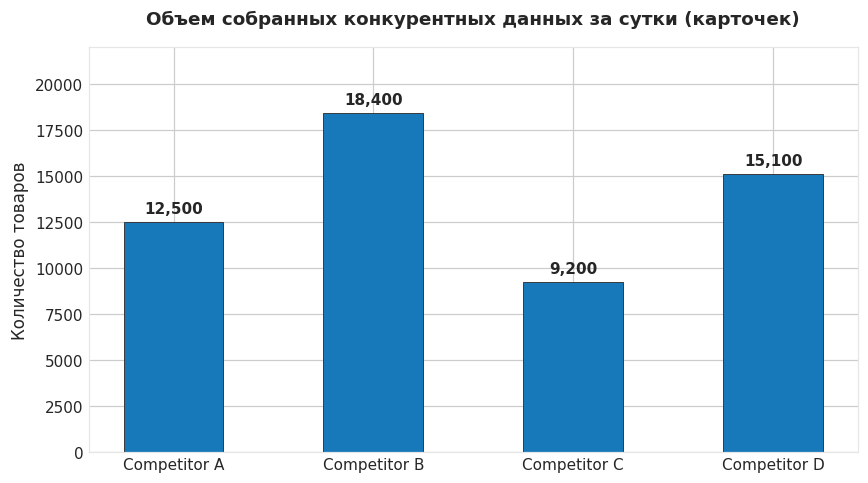

In [3]:
# Визуализация объемов сбора данных
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=110)

bars = ax.bar(scraping_metrics['Источник (Маркетплейс)'], scraping_metrics['Собрано карточек'],
              color=PRIMARY, edgecolor='#333333', linewidth=0.6, width=0.5)

ax.set_title("Объем собранных конкурентных данных за сутки (карточек)", fontsize=12, fontweight='bold', pad=15)
ax.set_ylabel("Количество товаров", fontsize=11)
ax.set_ylim(0, 22000)

for b in bars:
    h = b.get_height()
    ax.annotate(f"{h:,}", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 4),
                 textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Суммарный объем спарсенных данных
Посчитайте общее количество собранных карточек товаров по всем 4 маркетплейсам.

In [4]:
### ВАШ КОД ЗДЕСЬ
total_scraped = scraping_metrics['Собрано карточек'].sum()
print(f"Всего собрано позиций: {total_scraped:,}")

assert total_scraped == 55200, "Сумма должна равняться 55,200"
print("✅ Тест успешно пройден: конвейер сбора данных работает штатно!")

Всего собрано позиций: 55,200
✅ Тест успешно пройден: конвейер сбора данных работает штатно!


### 💡 Этичный парсинг и robots.txt
Агенты должны строго соблюдать задержки между запросами (не менее 1–2 секунд) и проверять `robots.txt`, чтобы не создавать паразитной нагрузки на серверы источников.